# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [15]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [16]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

scenario
blob      845
stripe    655
dtype: int64

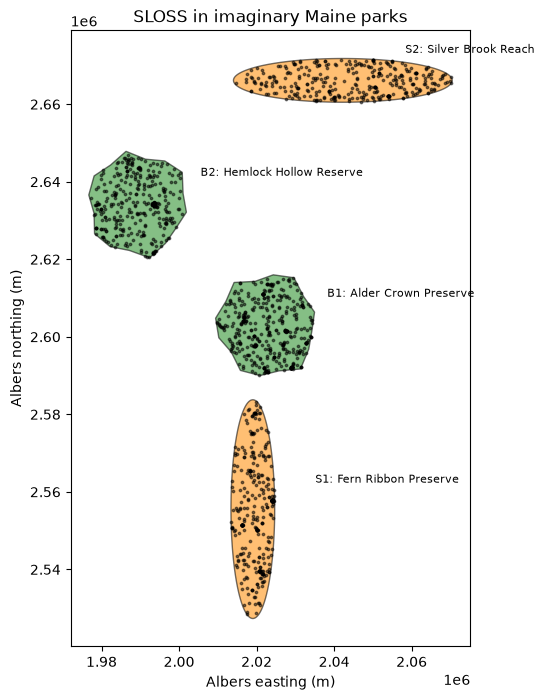

In [17]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().

display(records.groupby("scenario").size())

# Plot the parks and occurrence points; label B1, B2, S1, and S2.
fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(f"{row.Index}: {row.park_name}", (anchor.x, anchor.y),
                xytext=(45, 20), textcoords="offset points", fontsize=8)
ax.set(title="SLOSS in imaginary Maine parks",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer: The total area is held equal between both disigns. The location and the distance between each design differs. I think that the stripe will capture more species because its design is more likely to cover a larger variation in habitat. 

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [18]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)


species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer: There are 66 species in the whole data set. Anaxyrus americanus is seemingly evenly distriuted through B1, B2 and S1 but has 1/4 of the observations in S2.*

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [19]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


<BarContainer object of 4 artists>

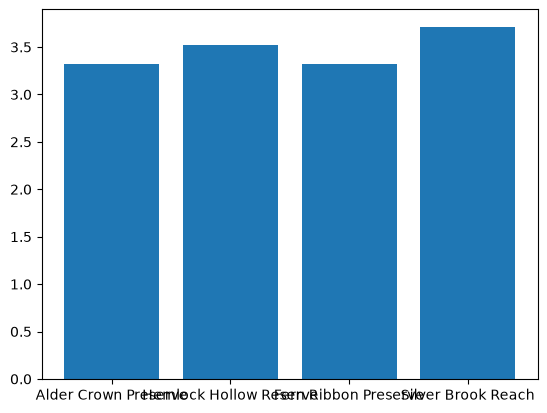

In [20]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)

# Add park names and scenarios from parks.
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
# Add evenness = np.exp(shannon) / richness, as in Lab10.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
# Display the table and make a simple richness or Shannon plot.
display(park_metrics)

plt.bar(park_metrics["park_name"], park_metrics["shannon"])

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer: Yes, Silver Brook Reach has the highest diversity and evenness. It would make both of these metrics smaller.*

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [21]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)
# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})
# For each design, find its two rows in park_metrics.
for design in designs:
    local_parks = park_metrics[park_metrics.scenario == design]
    alpha = local_parks.richness.mean()
    gamma = design_metrics.loc[design, "gamma_richness"]
    design_metrics.loc[design, "mean_park_alpha"] = alpha
    design_metrics.loc[design, "beta_ratio"] = gamma / alpha
    design_metrics.loc[design, "sum_park_richness"] = local_parks.richness.sum()
    design_metrics.loc[design, "area_km2"] = parks[parks.scenario == design].measured_km2.sum()

# Calculate mean_park_alpha and beta_ratio, then display design_metrics.


display(design_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
blob,845.0,60.0,3.460793,52.5,1.142857,105.0,1000.000589
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

*Your answer: Stripe has a higher gamme diversity. The alpha is also higher for stripe and the gamme richness is greater too. pooled richness is smaller because there is overlap in species between parks.  *
    
List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.


In [22]:
# Make blob_species and stripe_species from design_counts.
blob_counts = design_counts.loc["blob"]
stripe_counts = design_counts.loc["stripe"]
blob_species = set(blob_counts[blob_counts > 0].index)
stripe_species = set(stripe_counts[stripe_counts > 0].index)

# Print species unique to each design.
print("Only in the blob park:", sorted(blob_species - stripe_species))
print("Only in the stripe parks:", sorted(stripe_species - blob_species))
print("In both strategies:", len(blob_species & stripe_species))



Only in the blob park: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in the stripe parks: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
In both strategies: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [23]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.

jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)

# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )
# Display the table.
display(jaccard_distances.round(2))

B1 versus B2: 0.25


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer: the stripe parks have bigger differences in species. This does agree with the beta ratios as the beta ratio for stripe is higher. Jaccard alone cannot distinguish because it cant account for what is causing the simmilarity. *

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [24]:
from scipy.spatial.distance import braycurtis
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))
# For each within-design pair, divide each row by its sum and compare again.
a_counts = community.loc["B1"]
b_counts = community.loc["B2"]
a_frequencies = a_counts / a_counts.sum()
b_frequencies = b_counts / b_counts.sum()
print("B1 versus B2, relative frequencies:", braycurtis(a_frequencies, b_frequencies))


B1 versus B2: 0.19763313609467456


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


B1 versus B2, relative frequencies: 0.19325497409210204


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer: Yes it does. Bray curtis adds abundance. unequal record totals can effect its values because bray curtis is foccused on abuandce so unequal records will skew abundance towards parks with higher effort. relative frequency standarizes this. *

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [25]:
equal_n = records.groupby("scenario").size().min()

rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []
    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=True, random_state=repeat)
        richness_samples.append(sample.species.nunique())

# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)

# Use np.mean and np.quantile, then display the table.

display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,53.63,50.0,58.0
stripe,655.0,56.48,52.0,61.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer: No, it keeps it the same and maybe even makes it stronger. there are still issues because we dont know which park in the blob was more biased sampling wise. *

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [26]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
print("Record-rare species:", rare_species)


,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Record-rare species: ['Ambystoma laterale', 'Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton evergreenii', 'Fictotriton moonensis', 'Fictotriton thorni', 'Fictotriton vernalensis', 'Imaginarana emberi', 'Imaginarana fernensis', 'Imaginarana granitica', 'Imaginarana humicola', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Lithobates pipiens', 'Rana arvalis', 'Sylvophantoma argentea', 'Sylvophantoma cedrina', 'Sylvophantoma echinata', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii', 'Sylvophantoma inverna', 'Sylvophantoma noctiluca', 'Sylvophantoma sprucea', 'Sylvophantoma willowii']


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [27]:
# Copy the restriction_metrics function from Lab10.
def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results

# Calculate park_restriction = restriction_metrics(community).
park_restriction = restriction_metrics(community)
# Display park_metrics.join(park_restriction).
display(park_metrics.join(park_restriction))
# For each design, loop through rare_species.

# Count a species once if design_counts.loc[design, species] > 0.

,n_records,richness,shannon,park_name,scenario,evenness,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136,4.0,19.500000,0.342105,17.0


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer: Yes, it seems that parks with higher we has higher cwe. Stripe design seems to capture more record rare species. These results do not establish a species is endemic to a park because they are just records of occurence. not complete surveys of each area. Invented species may increaese CE or CWE if these invented records only occur in 1 park and be misleading. 

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [28]:
output_dir = Path("outputs/Assignment11")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").


park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
species_context.to_csv(output_dir / "species_context.csv")
jaccard_distances.to_csv(output_dir / "jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "bray_curtis.csv")
rarefaction.to_csv(output_dir / "rarefaction.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:

   I would recommend using the stripes conservation strategy. The stripes have a higher Alpha, gamma, beta diversity than the  blob. The higher alpha diversity indicates that the individual sites of the stripes have higher richness than the individual sites of the blobs. The gamma diversity indicates that the combined stripes have more diversity than the combined blobs. The beta diversity indicates that there are greater differences in the stripes than in the blobs. All of these measures of diversity are positives so we want them to be higher. They all support the stripe design. 
    Beyond these metrics, both the mean Shannon diversity and the mean evenness is greater for the stripe design. While they do differ between all four, the mean of each indicates that the stripes is the better option. The Jaccard is also higher for stripes indicating that the stripes cover a wider range of species, which is also better. I am less interested in the results of the bray-curtis as these are reliant on abundance. Our sampling method makes this not super informative. 
    Rareification does not change the result. The stripes have more rare species combined. Rarity adds the idea that a conservation area harbors uncommon or rare species. This may be because they are restricted to these specific areas, possibly due to biological or environmental reasons. This is important because it helps describe if a conservation area is harboring endangered or important species. If this is the case then we should consider using that strategy. This all continues to support the stripe strategy. 
    The use of these four parks does not allow us to determine a causal relationship between shape and diversity. I think it would be important to examine how the location of parks may impact these results. The 2 blobs are closer together in space. This would of course impact something like jaccard dissimilarity. This would likely impact diversity regardless of the shape of the actual conservation area. To do a better job testing this, and to try to isolate shape, it may be best to make sure the parks are equidistant apart and in the same region. The region the parks are in should also be examined to confirm it is relatively uniform throughout and that parks are not in separate biological areas or ecosystems. 


*